# Session 4 · Advanced Supervised Learning: Classification Techniques

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-04-advanced-classification-techniques.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: Gini and information gain by hand

In [1]:
"""Compute Gini impurity, entropy and the information gain of candidate splits by hand."""
import numpy as np

def gini(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)

def entropy(labels):
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return -np.sum(p * np.log2(p))

def gain(parent, left, right, measure=gini):
    n = len(parent)
    return measure(parent) - (len(left) / n * measure(left) + len(right) / n * measure(right))

# 10 customers: did they buy the premium plan? (1 = yes)
age     = np.array([22, 25, 28, 35, 38, 42, 47, 51, 55, 60])
salary  = np.array([30, 45, 32, 80, 95, 40, 120, 85, 38, 110])   # thousand Rs
bought  = np.array([0, 0, 0, 1, 1, 0, 1, 1, 0, 1])

print(f"parent: Gini = {gini(bought):.3f}, entropy = {entropy(bought):.3f}")
for name, col in [("age", age), ("salary", salary)]:
    best = max(((gain(bought, bought[col <= t], bought[col > t]), t) for t in np.unique(col)[:-1]))
    print(f"best split on {name:<6}: <= {best[1]:>3}  gain (Gini) = {best[0]:.3f}")
t = 45
print(f"\nsalary <= {t}: left {bought[salary <= t]}, right {bought[salary > t]}")
print(f"info gain (entropy) = {gain(bought, bought[salary <= t], bought[salary > t], entropy):.3f}")

parent: Gini = 0.500, entropy = 1.000
best split on age   : <=  28  gain (Gini) = 0.214
best split on salary: <=  45  gain (Gini) = 0.500

salary <= 45: left [0 0 0 0 0], right [1 1 1 1 1]
info gain (entropy) = 1.000


### Example 2 · Intermediate: tree depth, pruning and the readable tree

In [2]:
"""Effect of max_depth on a decision tree, cost-complexity pruning, and printing the rules."""
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

data = load_breast_cancer()
X_tr, X_te, y_tr, y_te = train_test_split(data.data, data.target, test_size=.3, random_state=0, stratify=data.target)

print("depth  leaves  train acc  test acc")
for d in [1, 2, 3, 5, 8, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_tr, y_tr)
    print(f"{str(d):>5}  {t.get_n_leaves():>6}  {t.score(X_tr, y_tr):>9.3f}  {t.score(X_te, y_te):>8.3f}")

path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_tr, y_tr)
print("\nccp_alpha  leaves  test acc")
for a in path.ccp_alphas[::4]:
    t = DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(X_tr, y_tr)
    print(f"{a:9.4f}  {t.get_n_leaves():>6}  {t.score(X_te, y_te):.3f}")

small = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
print("\n" + export_text(small, feature_names=list(data.feature_names)))

depth  leaves  train acc  test acc
    1       2      0.932     0.889
    2       4      0.942     0.906
    3       8      0.980     0.901
    5      15      0.997     0.912
    8      16      1.000     0.906
 None      16      1.000     0.906

ccp_alpha  leaves  test acc
   0.0000      16  0.906
   0.0049      10  0.912
   0.0196       4  0.901

|--- worst perimeter <= 106.10
|   |--- worst concave points <= 0.16
|   |   |--- class: 1
|   |--- worst concave points >  0.16
|   |   |--- class: 0
|--- worst perimeter >  106.10
|   |--- worst concave points <= 0.14
|   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- class: 0



### Example 3 · Intermediate: ensembles head to head

In [3]:
"""Single tree vs bagging, random forest, AdaBoost, gradient boosting, voting and stacking."""
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                              HistGradientBoostingClassifier, VotingClassifier, StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = make_classification(n_samples=1500, n_features=20, n_informative=8, n_redundant=4,
                           flip_y=0.05, class_sep=0.8, random_state=0)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
svm = make_pipeline(StandardScaler(), SVC(probability=True, random_state=0))
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
rf = RandomForestClassifier(300, random_state=0, n_jobs=-1)
models = {
    "Single decision tree": DecisionTreeClassifier(random_state=0),
    "Bagging (100 trees)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0, n_jobs=-1),
    "Random forest": rf,
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=0),
    "Gradient boosting (hist)": HistGradientBoostingClassifier(random_state=0),
    "Soft voting (LR+SVM+RF)": VotingClassifier([("lr", lr), ("svm", svm), ("rf", rf)], voting="soft", n_jobs=-1),
    "Stacking (meta = LR)": StackingClassifier([("svm", svm), ("rf", rf)], final_estimator=LogisticRegression(), n_jobs=-1),
}
print(f"{'model':<26}{'CV accuracy':>12}")
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=cv)
    print(f"{name:<26}{s.mean():>8.3f} ± {s.std():.3f}")

oob = RandomForestClassifier(300, oob_score=True, random_state=0, n_jobs=-1).fit(X, y)
print(f"\nrandom forest out-of-bag score: {oob.oob_score_:.3f} (free validation, no extra split)")

model                      CV accuracy


Single decision tree         0.789 ± 0.016


Bagging (100 trees)          0.880 ± 0.017


Random forest                0.892 ± 0.016


AdaBoost                     0.820 ± 0.012


Gradient boosting (hist)     0.880 ± 0.013


Soft voting (LR+SVM+RF)      0.877 ± 0.016


Stacking (meta = LR)         0.894 ± 0.015



random forest out-of-bag score: 0.898 (free validation, no extra split)


### Example 4 · Advanced: SVM margins, C and the kernel trick

kernel   C      gamma  support vectors  train acc  test acc
linear    1    scale              273      0.582     0.500


poly      1    scale               35      0.993     1.000
rbf       1      0.1              109      0.996     1.000


rbf       1        1               51      0.993     1.000
rbf     100       50              239      1.000     0.983


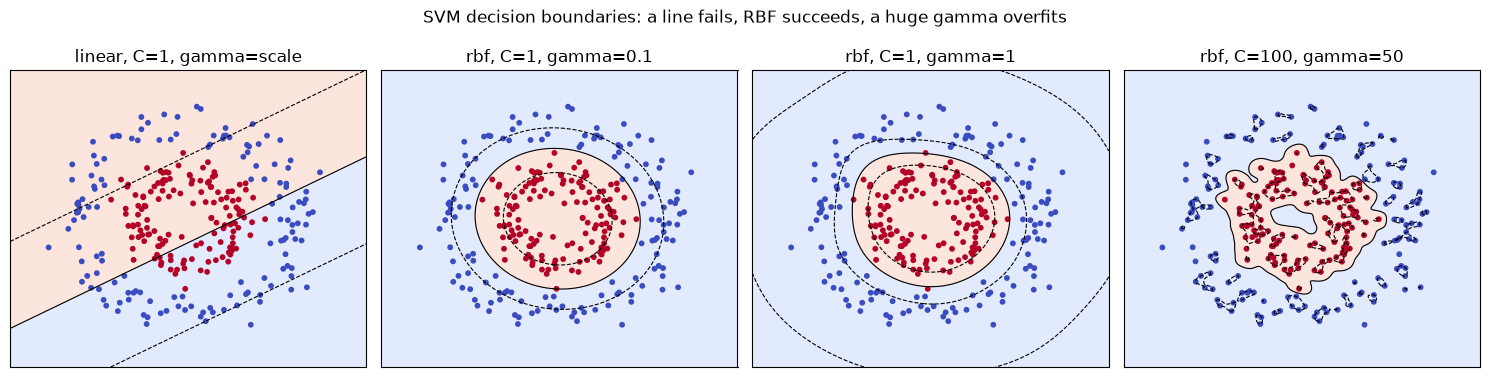


linear SVM after adding x1^2 + x2^2 as a 3rd feature: test acc = 1.000


In [4]:
"""Linear vs RBF SVM on ring-shaped data; the effect of C and gamma; a decision-boundary figure."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X, y = make_circles(n_samples=400, noise=0.12, factor=0.45, random_state=0)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.3, random_state=0)

print("kernel   C      gamma  support vectors  train acc  test acc")
configs = [("linear", 1, "scale"), ("poly", 1, "scale"), ("rbf", 1, 0.1), ("rbf", 1, 1), ("rbf", 100, 50)]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
xx, yy = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-1.6, 1.6, 300))
for i, (k, C, g) in enumerate(configs):
    m = make_pipeline(StandardScaler(), SVC(kernel=k, C=C, gamma=g, degree=2)).fit(X_tr, y_tr)
    nsv = m[-1].n_support_.sum()
    print(f"{k:<7}{C:>4}  {str(g):>7}  {nsv:>15}  {m.score(X_tr, y_tr):>9.3f}  {m.score(X_te, y_te):>8.3f}")
    if i in (0, 2, 3, 4):
        ax = axes[[0, 2, 3, 4].index(i)]
        Z = m.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.contourf(xx, yy, Z > 0, alpha=.25, cmap="coolwarm"); ax.contour(xx, yy, Z, levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k", linewidths=.8)
        ax.scatter(X_tr[:, 0], X_tr[:, 1], c=y_tr, cmap="coolwarm", s=10)
        ax.set_title(f"{k}, C={C}, gamma={g}"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("SVM decision boundaries: a line fails, RBF succeeds, a huge gamma overfits")
fig.tight_layout(); fig.savefig("session-04_svm_kernels.png", dpi=110); plt.show()

# Why the kernel works: add the feature r^2 = x1^2 + x2^2 and the rings become linearly separable
r2 = (X ** 2).sum(axis=1).reshape(-1, 1)
lin = SVC(kernel="linear").fit(np.c_[X, r2][:280], y[:280])
print(f"\nlinear SVM after adding x1^2 + x2^2 as a 3rd feature: test acc = {lin.score(np.c_[X, r2][280:], y[280:]):.3f}")

### Example 5 · Advanced: grid search, random search, halving and nested CV

In [5]:
"""Hyperparameter tuning strategies compared on the same SVM: grid, random, halving, nested CV."""
import time
import numpy as np
from scipy.stats import loguniform
from sklearn.datasets import load_breast_cancer
from sklearn.experimental import enable_halving_search_cv  # noqa: F401  (activates Halving*)
from sklearn.model_selection import (GridSearchCV, RandomizedSearchCV, HalvingGridSearchCV,
                                     cross_val_score, train_test_split, StratifiedKFold)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, random_state=0, stratify=y)
pipe = make_pipeline(StandardScaler(), SVC())
grid = {"svc__C": np.logspace(-2, 3, 6), "svc__gamma": np.logspace(-4, 1, 6)}
cv = StratifiedKFold(5, shuffle=True, random_state=0)

searches = {
    "Grid search (36 combos)": GridSearchCV(pipe, grid, cv=cv),
    "Random search (12 draws)": RandomizedSearchCV(pipe, {"svc__C": loguniform(1e-2, 1e3), "svc__gamma": loguniform(1e-4, 10)},
                                                   n_iter=12, cv=cv, random_state=0),
    "Successive halving": HalvingGridSearchCV(pipe, grid, cv=cv, factor=3, random_state=0),
}
print(f"{'strategy':<26}{'fits':>6}{'time s':>8}{'best CV':>9}{'test':>7}  best params")
for name, s in searches.items():
    t0 = time.perf_counter(); s.fit(X_tr, y_tr); dt = time.perf_counter() - t0
    fits = len(s.cv_results_["params"]) * cv.get_n_splits()
    bp = {k.split("__")[1]: round(float(v), 4) for k, v in s.best_params_.items()}
    print(f"{name:<26}{fits:>6}{dt:>8.2f}{s.best_score_:>9.3f}{s.score(X_te, y_te):>7.3f}  {bp}")

# Nested CV: an honest estimate of 'grid search + SVM' as a whole procedure
outer = StratifiedKFold(5, shuffle=True, random_state=1)
nested = cross_val_score(GridSearchCV(pipe, grid, cv=3), X, y, cv=outer)
print(f"\nnested CV accuracy: {nested.mean():.3f} ± {nested.std():.3f}")

strategy                    fits  time s  best CV   test  best params


Grid search (36 combos)      180    1.40    0.986  0.958  {'C': 100.0, 'gamma': 0.001}


Random search (12 draws)      60    0.53    0.981  0.937  {'C': 658.1332, 'gamma': 0.0083}


Successive halving           260    0.74    0.989  0.972  {'C': 10.0, 'gamma': 0.01}



nested CV accuracy: 0.975 ± 0.012


### 🏙️ Real-life data problem: predicting telecom churn

churn rate: 0.25

model              CV AUC test AUC  churners in top 10%  lift


Decision tree       0.767    0.775               63.9%   2.6


Random forest       0.803    0.806               68.9%   2.8


Gradient boosting   0.800    0.800               70.0%   2.8


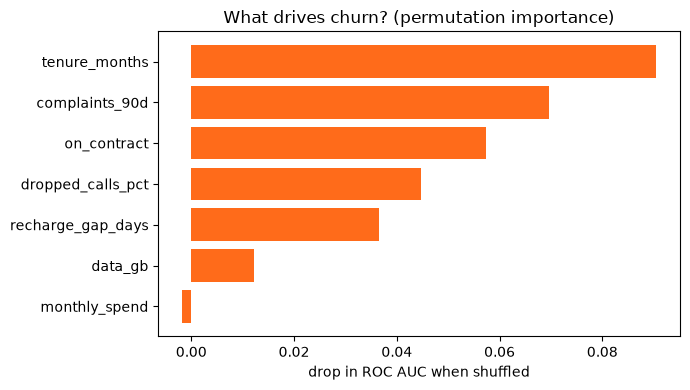


top drivers: ['tenure_months', 'complaints_90d', 'on_contract']


In [6]:
"""Real-life problem: telecom churn with tuned tree ensembles, lift in the top decile and feature importance."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(21)
n = 6000
df = pd.DataFrame({
    "tenure_months": rng.integers(1, 72, n),
    "monthly_spend": rng.gamma(3, 300, n).round(),
    "data_gb": rng.gamma(2, 4, n).round(1),
    "complaints_90d": rng.poisson(0.4, n),
    "dropped_calls_pct": rng.beta(2, 30, n).round(3) * 100,
    "on_contract": (rng.random(n) < .35).astype(int),
    "recharge_gap_days": rng.exponential(6, n).round(),
})
z = (-1.1 - 0.035 * df.tenure_months + 0.9 * df.complaints_90d + 0.12 * df.dropped_calls_pct
     - 1.4 * df.on_contract + 0.09 * df.recharge_gap_days - 0.04 * df.data_gb
     + 0.8 * ((df.monthly_spend > 1200) & (df.data_gb < 3)))                # paying a lot, using little
df["churn"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
print("churn rate:", round(df.churn.mean(), 3))

X, y = df.drop(columns="churn"), df["churn"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.3, random_state=0, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
searches = {
    "Decision tree": RandomizedSearchCV(DecisionTreeClassifier(random_state=0),
        {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [5, 10, 20, 50, 100]}, n_iter=15, cv=cv, scoring="roc_auc", random_state=0),
    "Random forest": RandomizedSearchCV(RandomForestClassifier(random_state=0, n_jobs=-1),
        {"n_estimators": [200, 400], "max_depth": [None, 8, 12], "min_samples_leaf": [1, 5, 10], "max_features": ["sqrt", 0.5]},
        n_iter=8, cv=cv, scoring="roc_auc", random_state=0),
    "Gradient boosting": RandomizedSearchCV(HistGradientBoostingClassifier(random_state=0),
        {"learning_rate": [0.03, 0.06, 0.1], "max_depth": [3, 5, None], "max_iter": [200, 400], "l2_regularization": [0, 1]},
        n_iter=8, cv=cv, scoring="roc_auc", random_state=0),
}
base_rate = y_te.mean()
print(f"\n{'model':<18}{'CV AUC':>7}{'test AUC':>9}{'churners in top 10%':>21}{'lift':>6}")
for name, s in searches.items():
    s.fit(X_tr, y_tr)
    p = s.predict_proba(X_te)[:, 1]
    top = np.argsort(-p)[: len(p) // 10]
    hit = y_te.values[top].mean()
    print(f"{name:<18}{s.best_score_:>7.3f}{roc_auc_score(y_te, p):>9.3f}{hit:>20.1%}{hit / base_rate:>6.1f}")

best = searches["Gradient boosting"].best_estimator_
imp = permutation_importance(best, X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=0)
order = imp.importances_mean.argsort()
plt.figure(figsize=(7, 4))
plt.barh(X.columns[order], imp.importances_mean[order], color="#FF6B1A")
plt.xlabel("drop in ROC AUC when shuffled"); plt.title("What drives churn? (permutation importance)")
plt.tight_layout(); plt.savefig("session-04_churn_importance.png", dpi=110); plt.show()
print("\ntop drivers:", list(X.columns[order[::-1][:3]]))

### 🧩 Mini project: loan approval classifier with tuned ensembles

In [7]:
"""Mini project: tune three classifiers for loan approval, compare on a test set, export decision rules."""
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report

rng = np.random.default_rng(8)
n = 2000
X = pd.DataFrame({"income_k": rng.lognormal(4.2, .4, n), "credit_score": rng.normal(650, 70, n).clip(300, 850),
                  "debt_ratio": rng.beta(2, 5, n), "years_job": rng.exponential(5, n)})
z = -2.4 + 0.04 * X.income_k + 0.024 * (X.credit_score - 600) - 10 * X.debt_ratio + 0.2 * X.years_job
y = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)                # 1 = approve (about half)
print("approval rate:", round(y.mean(), 3))
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, random_state=0, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

tuned = {
    "tree": GridSearchCV(DecisionTreeClassifier(random_state=0), {"max_depth": [2, 3, 4, 6], "min_samples_leaf": [10, 30]}, cv=cv),
    "forest": GridSearchCV(RandomForestClassifier(random_state=0, n_jobs=-1), {"n_estimators": [200], "min_samples_leaf": [1, 5, 15]}, cv=cv),
    "svm": GridSearchCV(make_pipeline(StandardScaler(), SVC()), {"svc__C": [0.3, 1, 3, 10], "svc__gamma": ["scale", 0.05]}, cv=cv),
}
for name, g in tuned.items():
    g.fit(X_tr, y_tr)
    print(f"{name:<7} best CV acc {g.best_score_:.3f} | test acc {g.score(X_te, y_te):.3f} | {g.best_params_}")
winner = max(tuned, key=lambda k: tuned[k].best_score_)
print(f"\nwinner by CV: {winner}\n")
print(classification_report(y_te, tuned[winner].predict(X_te), target_names=["decline", "approve"]))
# The tuned tree is deep; for a policy document fit a short depth-2 tree and accept a little less accuracy
policy = DecisionTreeClassifier(max_depth=2, min_samples_leaf=30, random_state=0).fit(X_tr, y_tr)
print(f"Readable depth-2 policy tree (test acc {policy.score(X_te, y_te):.3f}):")
print(export_text(policy, feature_names=list(X.columns), decimals=2))

approval rate: 0.488
tree    best CV acc 0.781 | test acc 0.770 | {'max_depth': 6, 'min_samples_leaf': 30}


forest  best CV acc 0.817 | test acc 0.794 | {'min_samples_leaf': 1, 'n_estimators': 200}


svm     best CV acc 0.841 | test acc 0.796 | {'svc__C': 0.3, 'svc__gamma': 'scale'}

winner by CV: svm

              precision    recall  f1-score   support

     decline       0.79      0.82      0.81       256
     approve       0.81      0.77      0.79       244

    accuracy                           0.80       500
   macro avg       0.80      0.80      0.80       500
weighted avg       0.80      0.80      0.80       500

Readable depth-2 policy tree (test acc 0.682):
|--- credit_score <= 652.87
|   |--- debt_ratio <= 0.24
|   |   |--- class: 0
|   |--- debt_ratio >  0.24
|   |   |--- class: 0
|--- credit_score >  652.87
|   |--- debt_ratio <= 0.34
|   |   |--- class: 1
|   |--- debt_ratio >  0.34
|   |   |--- class: 0

